### Load the validated summary

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("datasets")
OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9.2, 5.3),
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 10.5,
    "axes.titlesize": 13,
    "axes.labelsize": 10.5,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# Prefer the final summary export.
summary_path = DATA_DIR / "chapter4_summary.csv"

if not summary_path.exists():
    raise FileNotFoundError(
        "Place the validated chapter4_summary.csv in the datasets folder."
    )

summary = pd.read_csv(summary_path)

required_columns = [
    "VUs",
    "Avg_Latency_ms_Mean",
    "Avg_Latency_ms_SD",
    "P95_ms_Mean",
    "P95_ms_SD",
    "P99_ms_Mean",
    "P99_ms_SD",
    "RPS_Mean",
    "RPS_SD",
    "HTTP_Failed_Rate_pct_Mean",
    "HTTP_Failed_Rate_pct_SD",
    "Workflow_Success_Rate_pct_Mean",
    "Workflow_Success_Rate_pct_SD",
    "Workflow_Duration_Avg_ms_Mean",
    "Workflow_Duration_P95_ms_Mean",
    "Max_Latency_ms_Mean",
]

missing_columns = [
    column for column in required_columns
    if column not in summary.columns
]

if missing_columns:
    raise ValueError(
        "The summary CSV needs explicit column mapping before plotting. "
        f"Missing columns: {missing_columns}"
    )

summary = summary.sort_values("VUs").reset_index(drop=True)

display(summary[required_columns].round(3))

,VUs,Avg_Latency_ms_Mean,Avg_Latency_ms_SD,P95_ms_Mean,P95_ms_SD,P99_ms_Mean,P99_ms_SD,RPS_Mean,RPS_SD,HTTP_Failed_Rate_pct_Mean,HTTP_Failed_Rate_pct_SD,Workflow_Success_Rate_pct_Mean,Workflow_Success_Rate_pct_SD,Workflow_Duration_Avg_ms_Mean,Workflow_Duration_P95_ms_Mean,Max_Latency_ms_Mean
0,10,2395.138,915.259,6743.086,5758.272,21133.862,15358.587,2.870,1.007,1.876,1.512,96.848,2.624,9102.641,23339.917,30002.483
1,25,2151.510,696.896,4301.542,2568.689,19030.847,13675.997,7.430,1.682,1.448,1.365,97.371,2.332,8658.237,19221.833,30001.905
2,50,3130.009,620.399,8683.915,6855.524,16548.584,11999.258,11.521,1.992,1.506,2.285,97.781,3.114,11296.254,24397.050,30002.230
3,100,6064.829,468.197,13445.190,5443.004,21360.722,7529.868,12.894,0.549,1.942,2.888,96.964,4.074,20519.113,37664.400,28500.620


### Validate the plotting data

In [13]:
numeric_columns = [
    column for column in required_columns
    if column != "VUs"
]

print("Rows:", len(summary))
print("Missing values by column:")
display(summary[required_columns].isna().sum())

print("\nDuplicate workload levels:", summary["VUs"].duplicated().sum())

if summary["VUs"].duplicated().any():
    raise ValueError("Duplicate VU levels found. Resolve before plotting.")

if summary[required_columns].isna().any().any():
    raise ValueError(
        "Missing required plotting values found. Resolve or document "
        "the missingness before producing final thesis figures."
    )

if len(summary) != 4:
    print(
        "Warning: expected four workload levels. "
        "Check whether the final dataset matches the experimental design."
    )

Rows: 4
Missing values by column:


VUs                               0
Avg_Latency_ms_Mean               0
Avg_Latency_ms_SD                 0
P95_ms_Mean                       0
P95_ms_SD                         0
P99_ms_Mean                       0
P99_ms_SD                         0
RPS_Mean                          0
RPS_SD                            0
HTTP_Failed_Rate_pct_Mean         0
HTTP_Failed_Rate_pct_SD           0
Workflow_Success_Rate_pct_Mean    0
Workflow_Success_Rate_pct_SD      0
Workflow_Duration_Avg_ms_Mean     0
Workflow_Duration_P95_ms_Mean     0
Max_Latency_ms_Mean               0
dtype: int64


Duplicate workload levels: 0


### Mean response time

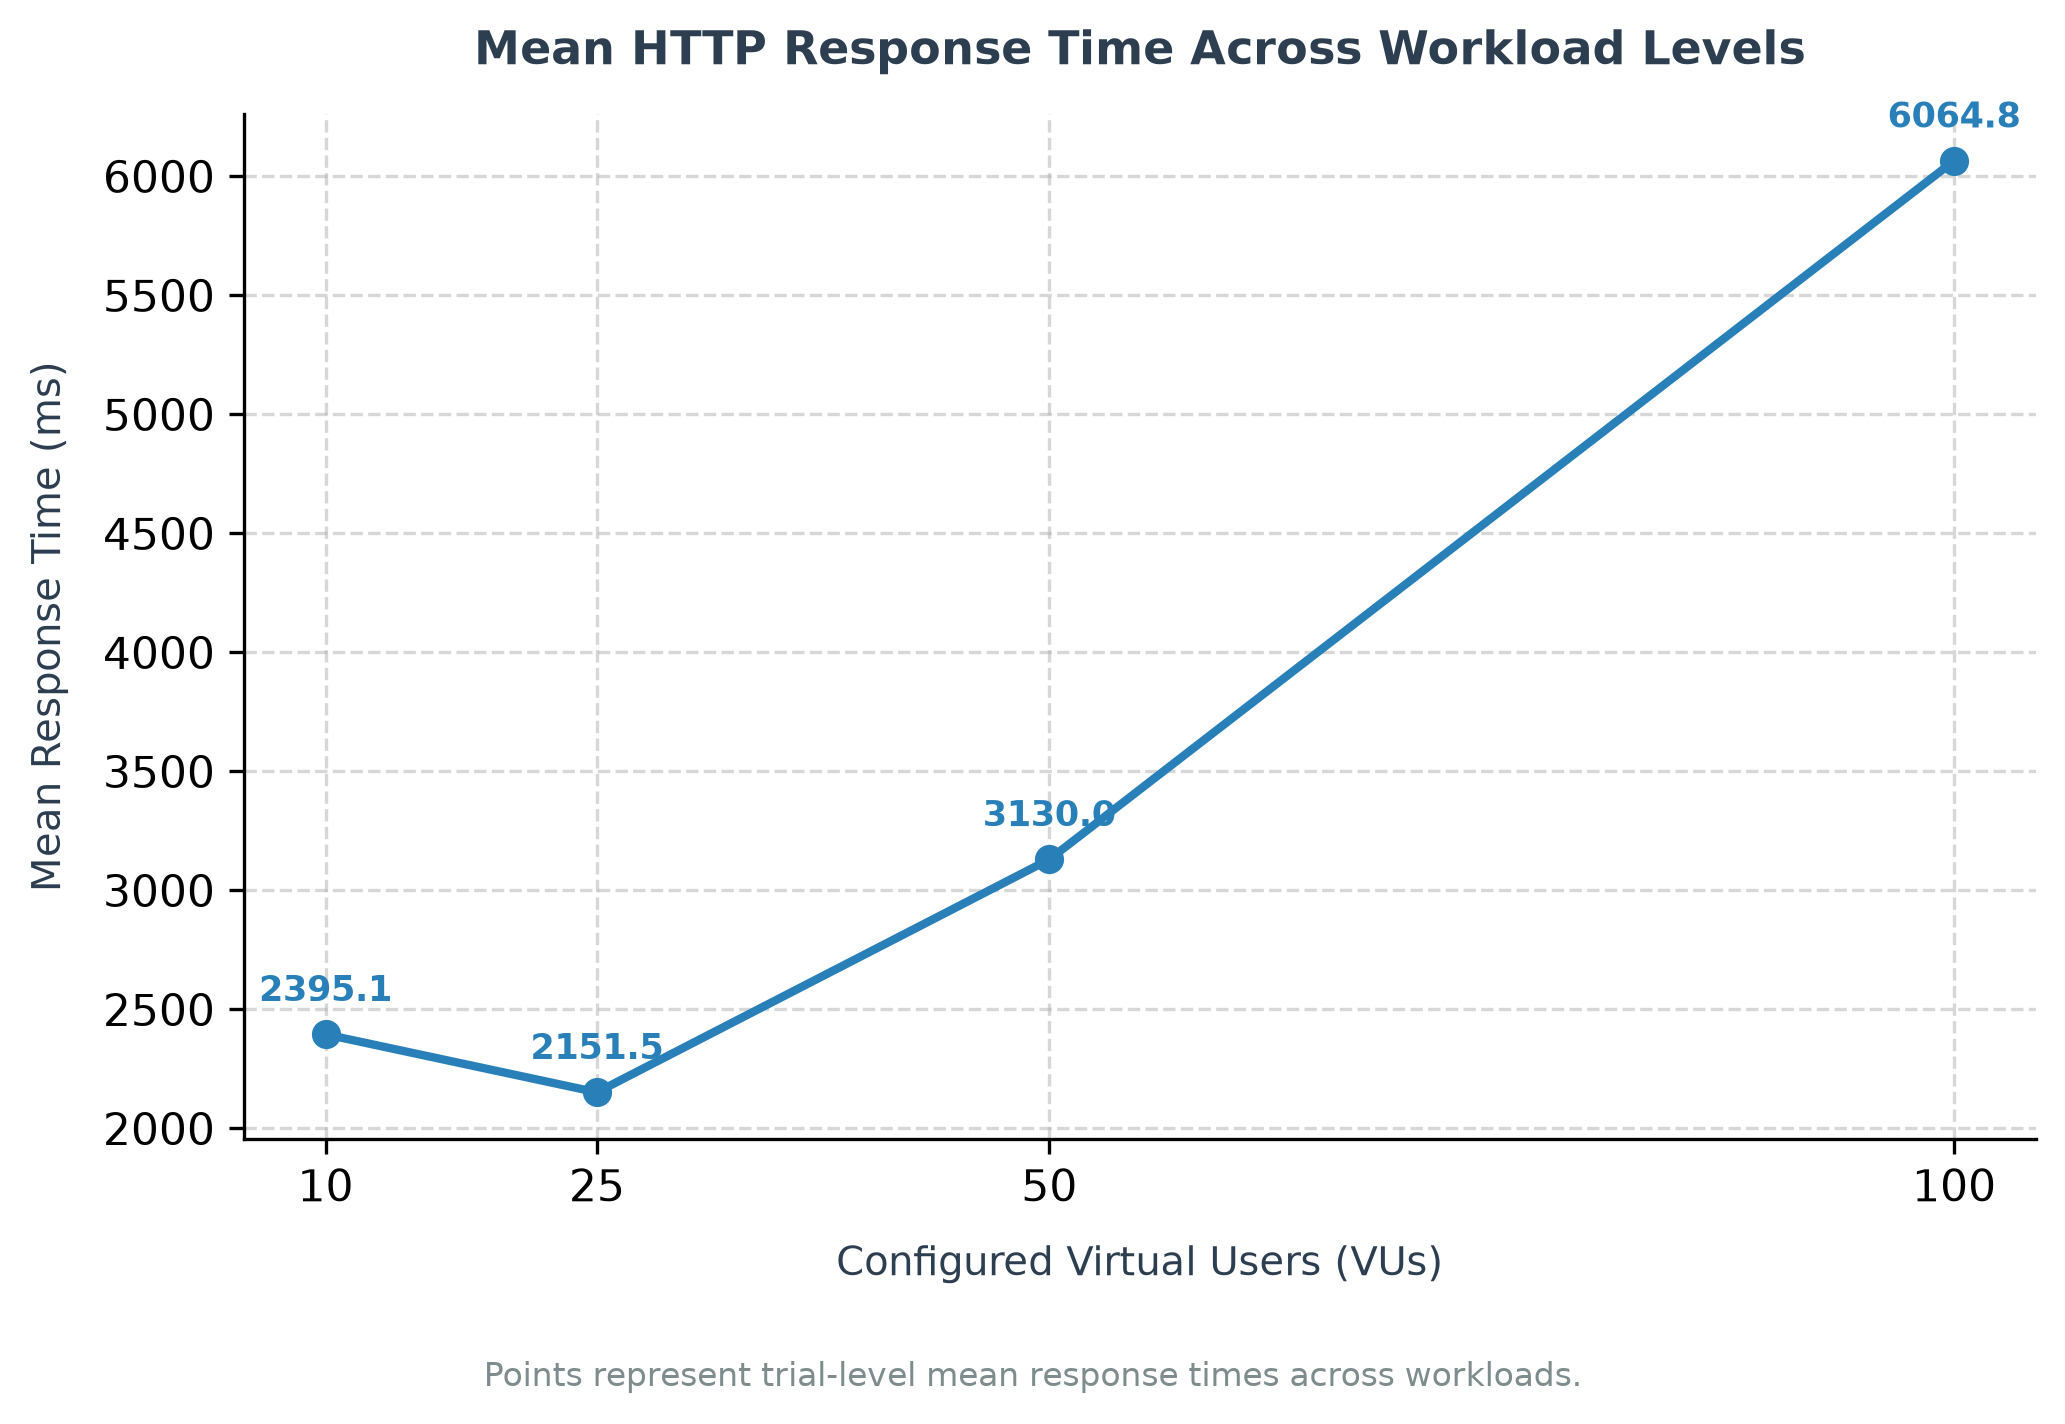

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x = summary["VUs"]
y = summary["Avg_Latency_ms_Mean"]

# Plot clean trend line without error bar tails
ax.plot(
    x, y,
    marker="o", markersize=6, linewidth=2,
    color="#2980b9", label="Mean Response Time"
)

# Add direct text labels above each data point for instant readability
for i, txt in enumerate(y):
    ax.annotate(
        f"{txt:.1f}", 
        (x.iloc[i], y.iloc[i]),
        textcoords="offset points", 
        xytext=(0, 8), 
        ha='center', 
        fontsize=8.5, 
        color="#2980b9",
        fontweight="700"
    )

ax.set_title("Mean HTTP Response Time Across Workload Levels", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Mean Response Time (ms)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_xticks(x)

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)

fig.text(
    0.5, -0.04,
    "Points represent trial-level mean response times across workloads.",
    ha="center",
    fontsize=8,
    color="#7f8c8d"
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_1_mean_response_time.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### P95 and P99 tail latency

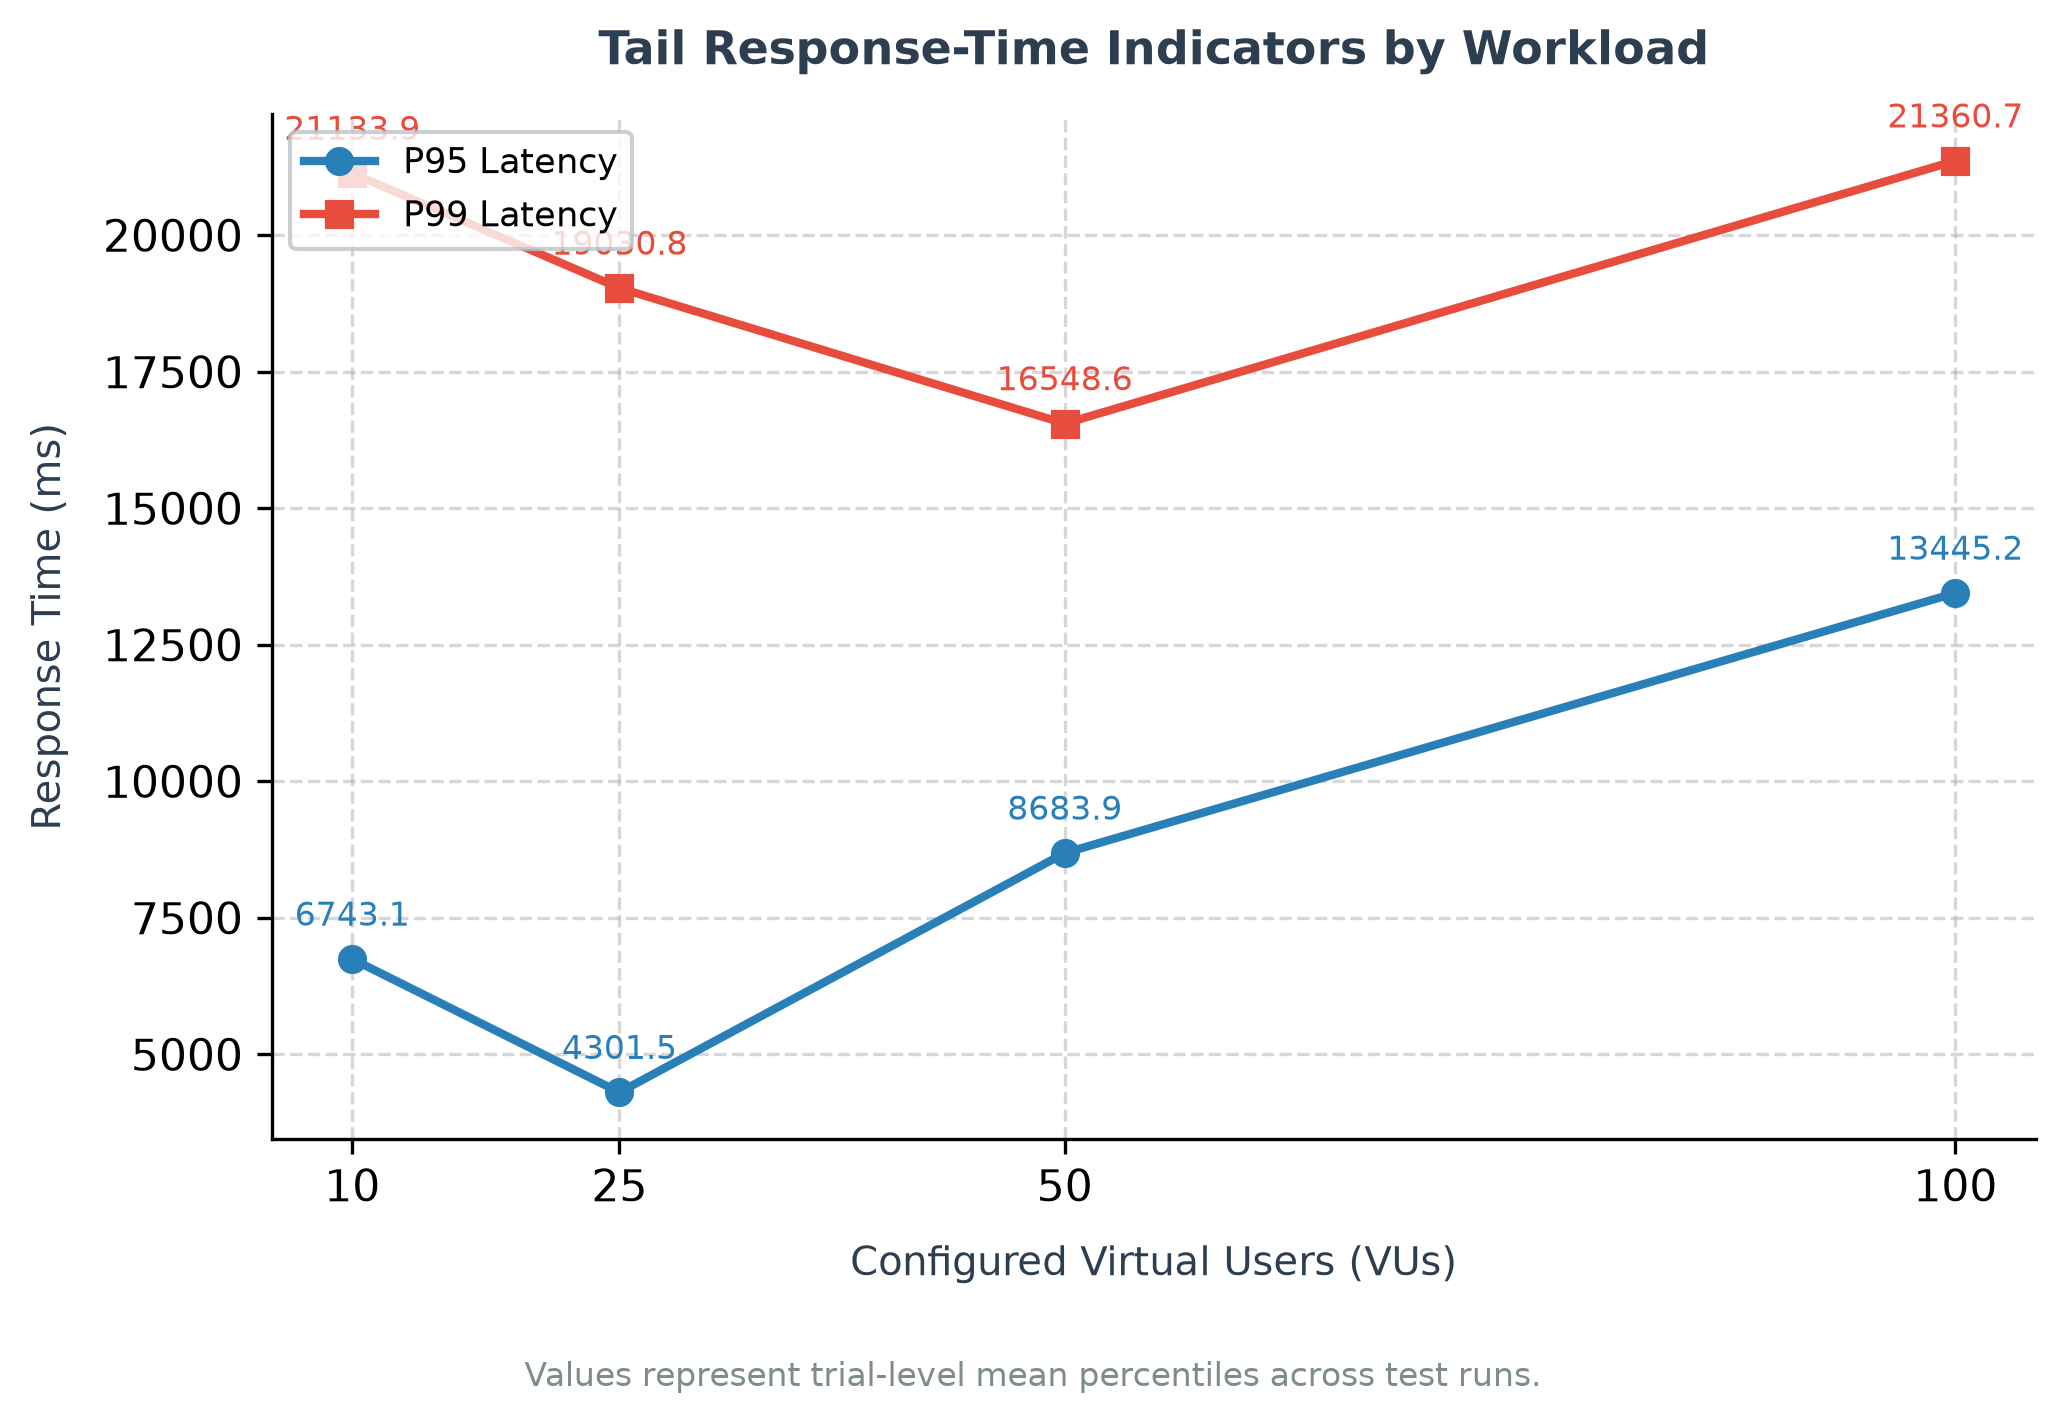

In [15]:

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x = summary["VUs"]

# Plot P95 with a clean, distinct marker and color
ax.plot(
    x, summary["P95_ms_Mean"],
    marker="o", markersize=6, linewidth=2,
    color="#2980b9", label="P95 Latency"
)

# Plot P99 with a clean, distinct marker and color
ax.plot(
    x, summary["P99_ms_Mean"],
    marker="s", markersize=6, linewidth=2,
    color="#e74c3c", label="P99 Latency"
)

# Add direct text labels above each data point for clarity
for i, txt in enumerate(summary["P95_ms_Mean"]):
    ax.annotate(f"{txt:.1f}", (x.iloc[i], summary["P95_ms_Mean"].iloc[i]),
                textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8, color="#2980b9")

for i, txt in enumerate(summary["P99_ms_Mean"]):
    ax.annotate(f"{txt:.1f}", (x.iloc[i], summary["P99_ms_Mean"].iloc[i]),
                textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8, color="#e74c3c")

ax.set_title("Tail Response-Time Indicators by Workload", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Response Time (ms)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_xticks(x)

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.legend(frameon=True, facecolor="white", edgecolor="#bdc3c7", fontsize=8.5, loc="upper left")

fig.text(
    0.5, -0.04,
    "Values represent trial-level mean percentiles across test runs.",
    ha="center",
    fontsize=8,
    color="#7f8c8d"
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_2_tail_latency.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### Throughput

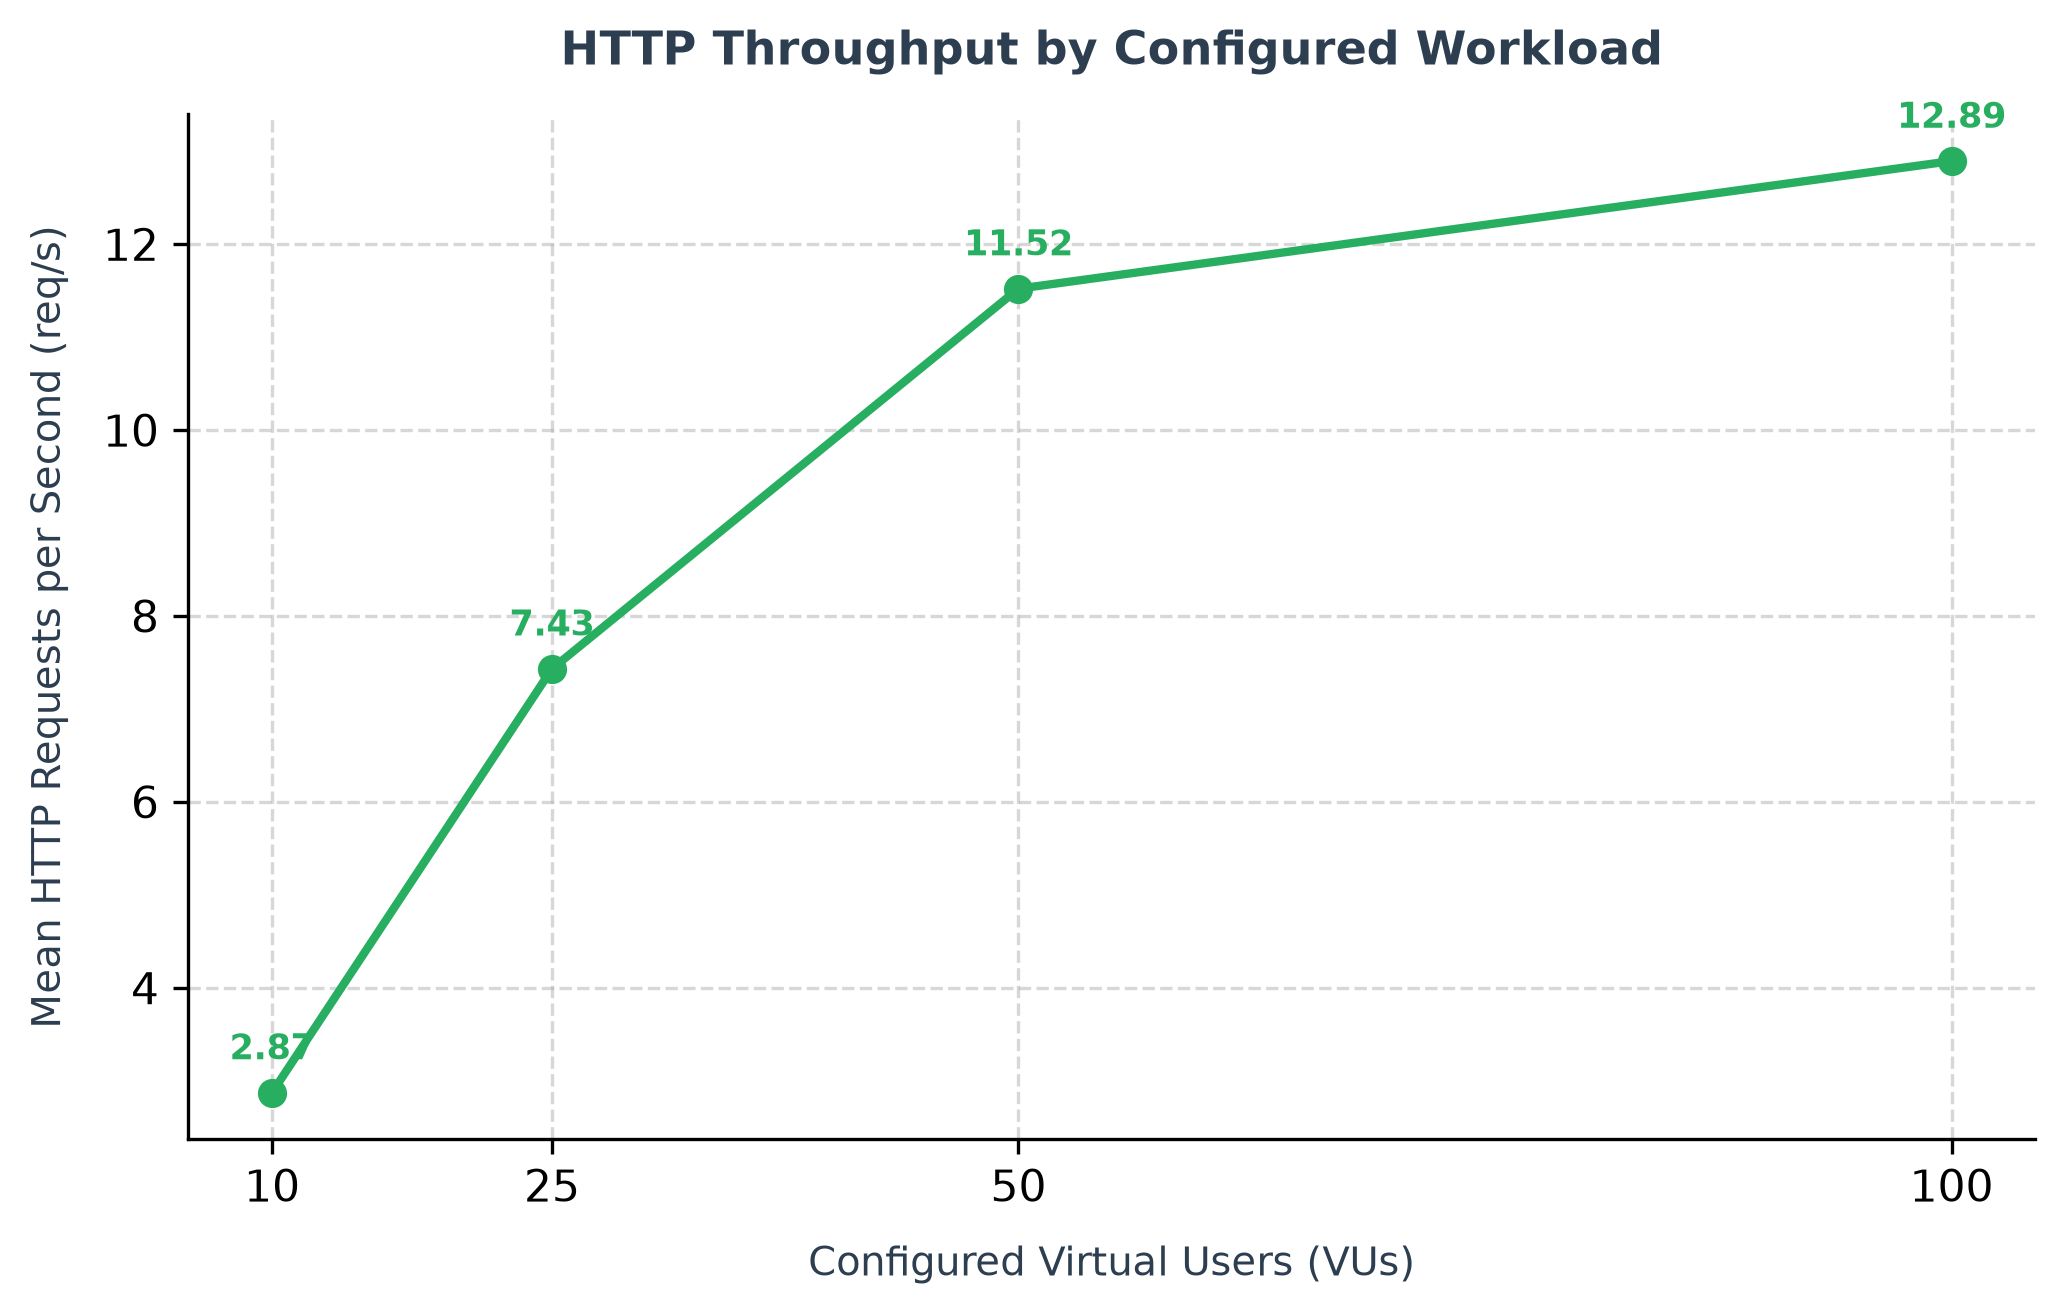

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x = summary["VUs"]
y = summary["RPS_Mean"]

# Plot clean trend line without error bar tails
ax.plot(
    x, y,
    marker="o", markersize=6, linewidth=2,
    color="#27ae60", label="Throughput (RPS)"
)

# Add direct text labels above each data point for instant readability
for i, txt in enumerate(y):
    ax.annotate(
        f"{txt:.2f}", 
        (x.iloc[i], y.iloc[i]),
        textcoords="offset points", 
        xytext=(0, 8), 
        ha='center', 
        fontsize=8.5, 
        color="#27ae60",
        fontweight="700"
    )

ax.set_title("HTTP Throughput by Configured Workload", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Mean HTTP Requests per Second (req/s)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_xticks(x)

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_3_throughput.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### HTTP failure rate

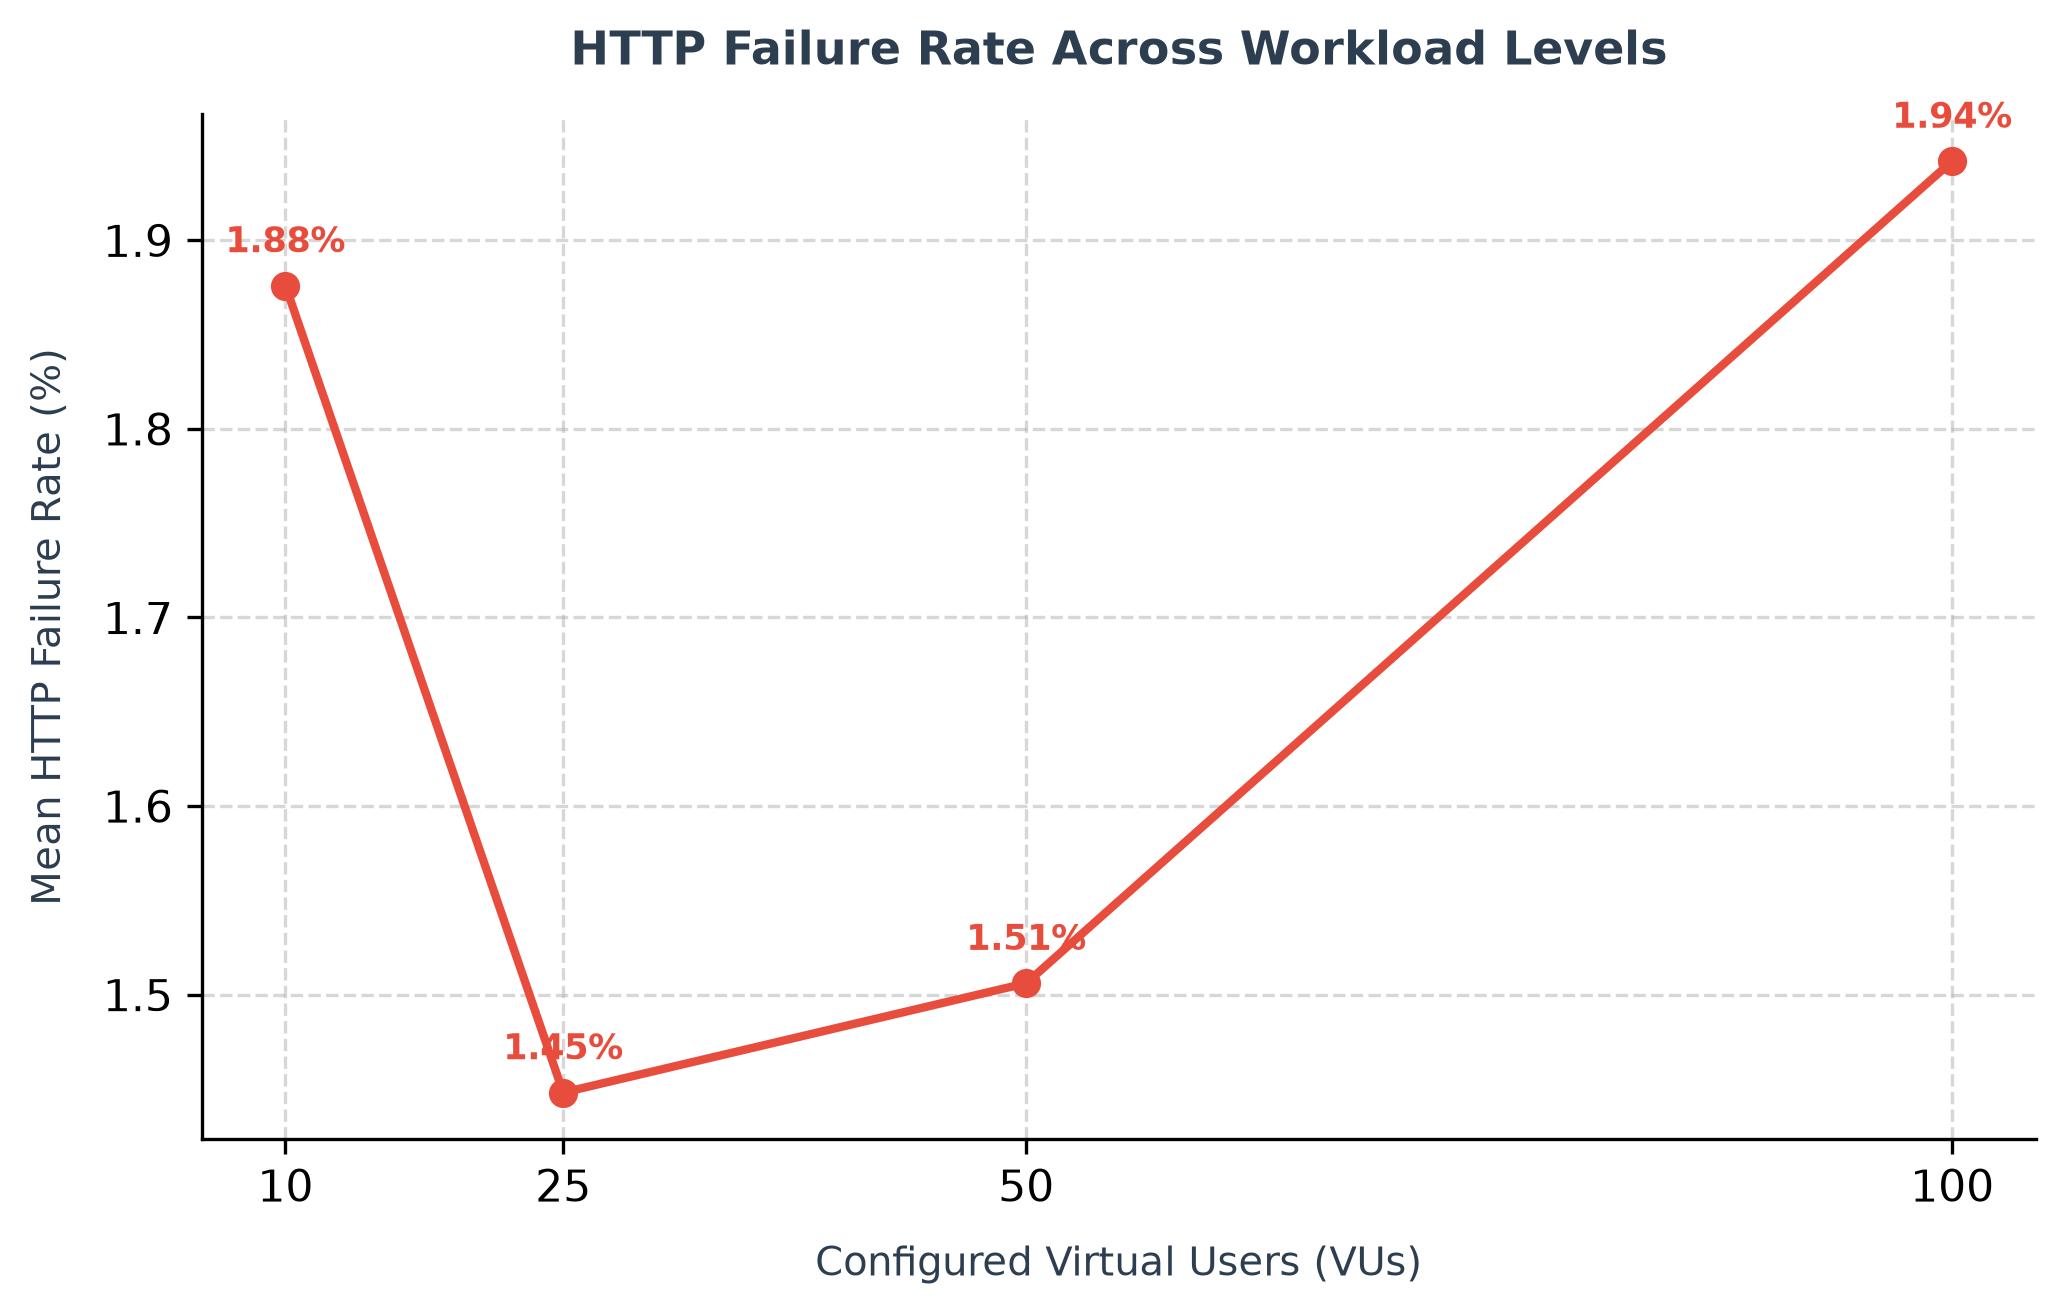

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x = summary["VUs"]
y = summary["HTTP_Failed_Rate_pct_Mean"]  # Corrected column name

# Plot clean trend line without error bar tails
ax.plot(
    x, y,
    marker="o", markersize=6, linewidth=2,
    color="#e74c3c", label="HTTP Failure Rate"
)

# Add direct text labels above each data point for instant readability
for i, txt in enumerate(y):
    ax.annotate(
        f"{txt:.2f}%", 
        (x.iloc[i], y.iloc[i]),
        textcoords="offset points", 
        xytext=(0, 8), 
        ha='center', 
        fontsize=8.5, 
        color="#e74c3c",
        fontweight="700"
    )

ax.set_title("HTTP Failure Rate Across Workload Levels", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Mean HTTP Failure Rate (%)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_xticks(x)

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_4_http_failure_rate.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### Workflow success rate

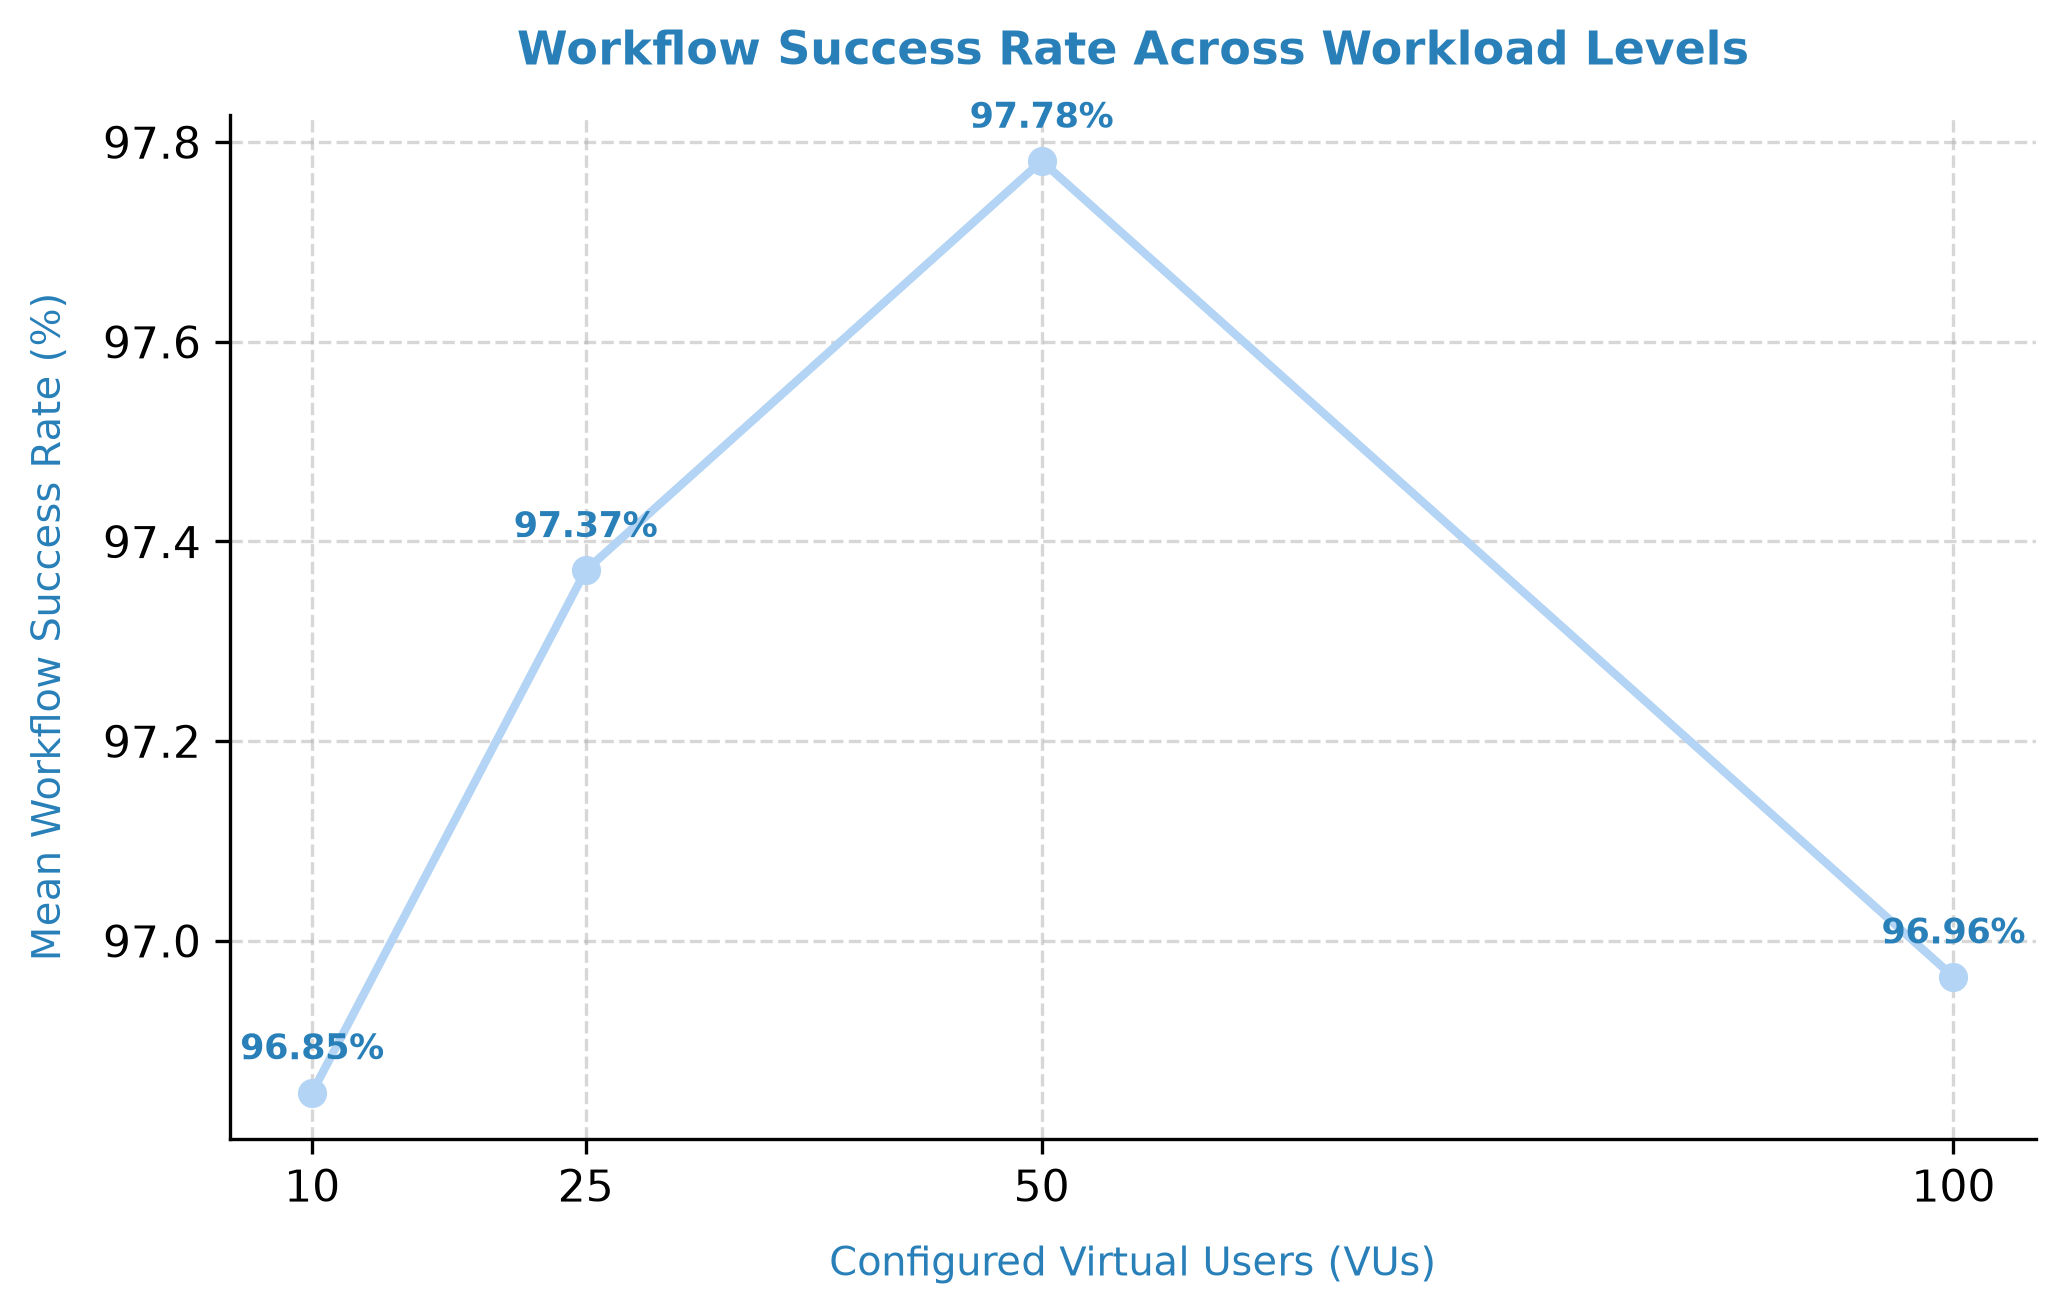

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x = summary["VUs"]
y = summary["Workflow_Success_Rate_pct_Mean"]  # Corrected column name

# Plot clean trend line without error bar tails
ax.plot(
    x, y,
    marker="o", markersize=6, linewidth=2,
    color="#B3D4F4", label="Workflow Success Rate"
)

# Add direct text labels above each data point for instant readability
for i, txt in enumerate(y):
    ax.annotate(
        f"{txt:.2f}%", 
        (x.iloc[i], y.iloc[i]),
        textcoords="offset points", 
        xytext=(0, 8), 
        ha='center', 
        fontsize=8.5, 
        color="#2980b9",
        fontweight="semibold"
    )

ax.set_title("Workflow Success Rate Across Workload Levels", fontsize=11, fontweight="bold", pad=12, color="#2980b9")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2980b9")
ax.set_ylabel("Mean Workflow Success Rate (%)", fontsize=9.5, labelpad=8, color="#2980b9")
ax.set_xticks(x)

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_5_workflow_success.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### Relative throughput and latency

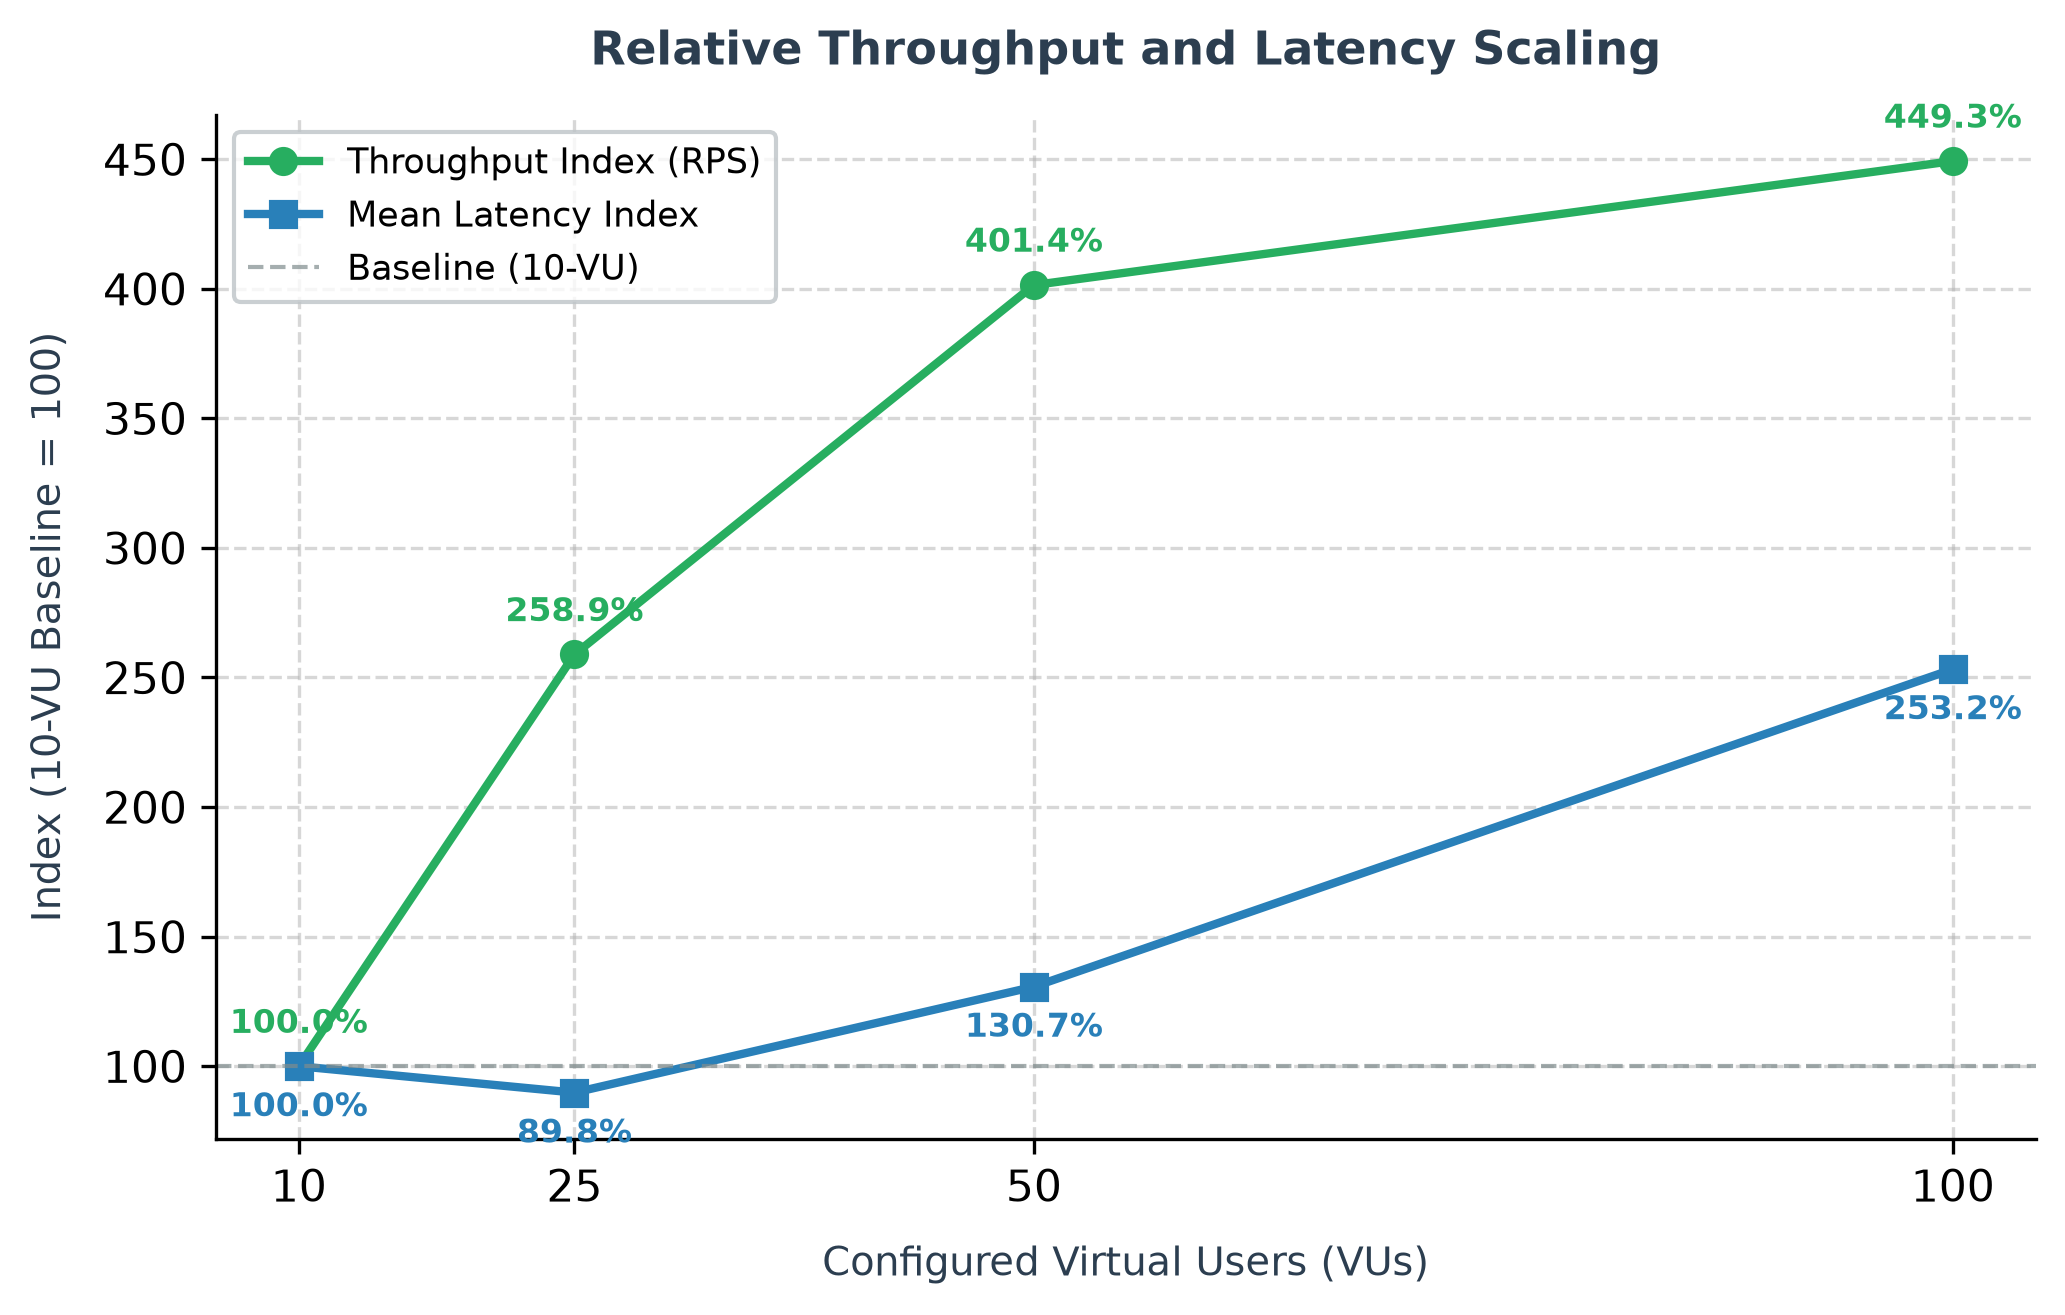

In [19]:
x = summary["VUs"]

throughput_index = (
    summary["RPS_Mean"] / summary["RPS_Mean"].iloc[0] * 100
)

latency_index = (
    summary["Avg_Latency_ms_Mean"]
    / summary["Avg_Latency_ms_Mean"].iloc[0]
    * 100
)

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

# Plot Throughput Index (Green)
ax.plot(
    x, throughput_index,
    marker="o", markersize=6, linewidth=2,
    color="#27ae60", label="Throughput Index (RPS)"
)

# Plot Latency Index (Blue/Slate)
ax.plot(
    x, latency_index,
    marker="s", markersize=6, linewidth=2,
    color="#2980b9", label="Mean Latency Index"
)

# Baseline reference line at 100%
ax.axhline(100, linestyle="--", color="#7f8c8d", linewidth=1, alpha=0.7, label="Baseline (10-VU)")

# Add direct data labels for throughput index
for i, txt in enumerate(throughput_index):
    ax.annotate(
        f"{txt:.1f}%", 
        (x.iloc[i], throughput_index.iloc[i]),
        textcoords="offset points", 
        xytext=(0, 8), 
        ha='center', 
        fontsize=8, 
        color="#27ae60",
        fontweight="700"
    )

# Add direct data labels for latency index
for i, txt in enumerate(latency_index):
    ax.annotate(
        f"{txt:.1f}%", 
        (x.iloc[i], latency_index.iloc[i]),
        textcoords="offset points", 
        xytext=(0, -12), 
        ha='center', 
        fontsize=8, 
        color="#2980b9",
        fontweight="700"
    )

ax.set_title("Relative Throughput and Latency Scaling", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Index (10-VU Baseline = 100)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_xticks(x)

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.legend(frameon=True, facecolor="white", edgecolor="#bdc3c7", fontsize=8.5, loc="best")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_6_relative_scaling.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### Workflow volume and duration

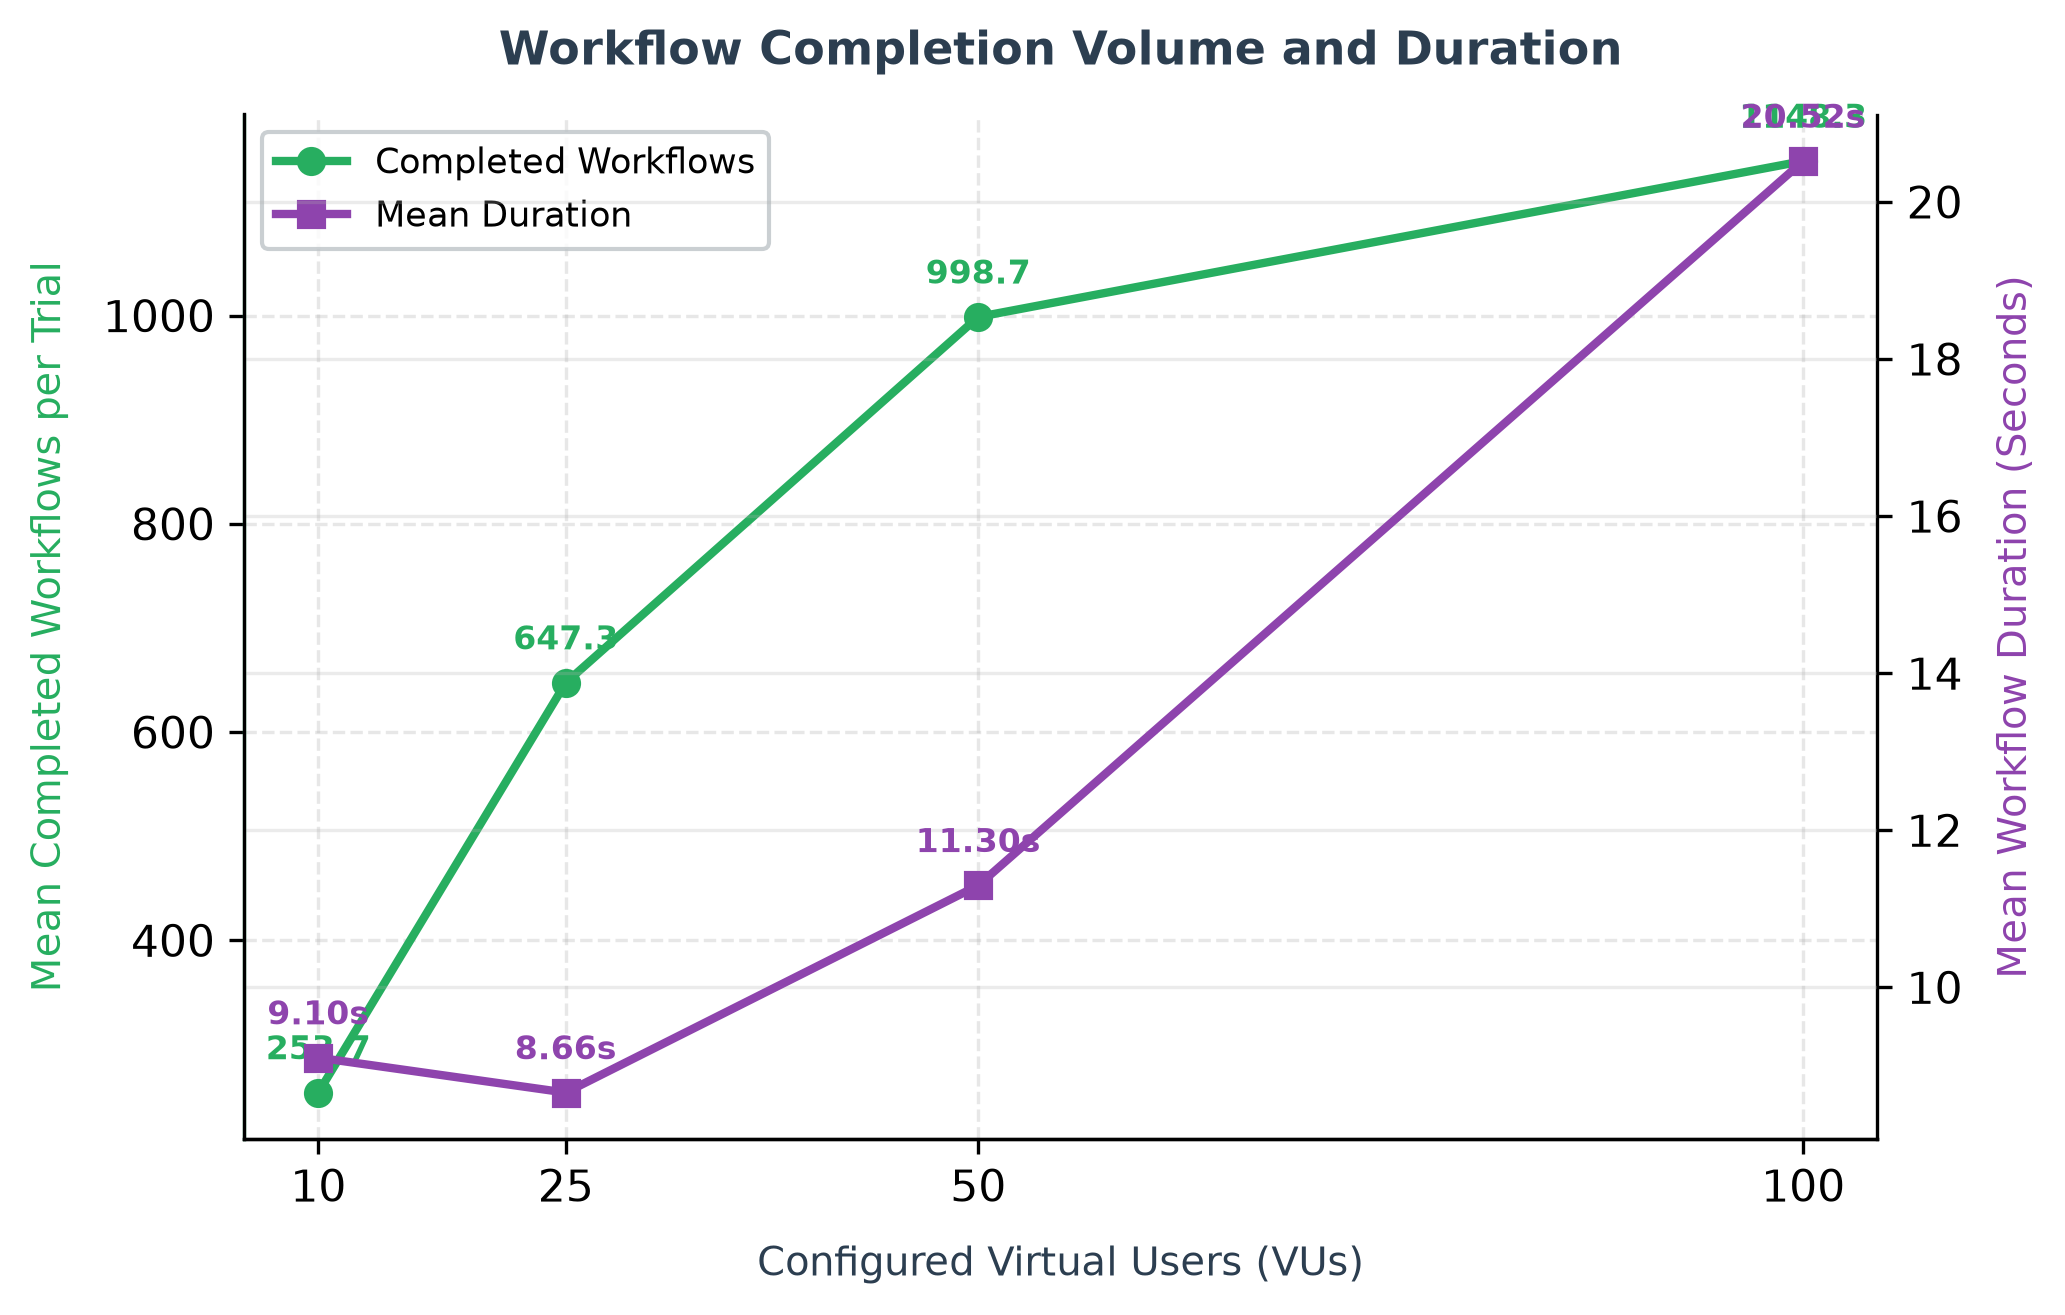

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x = summary["VUs"]
y1 = summary["Workflow_Completed_Mean"]
y2 = summary["Workflow_Duration_Avg_ms_Mean"] / 1000  # Convert ms to seconds

# --- Left Axis: Workflow Volume ---
line1 = ax.plot(
    x, y1,
    marker="o", markersize=6, linewidth=2,
    color="#27ae60", label="Completed Workflows"
)
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Mean Completed Workflows per Trial", fontsize=9.5, labelpad=8, color="#27ae60")
ax.set_xticks(x)

for i, txt in enumerate(y1):
    ax.annotate(
        f"{txt:.1f}", 
        (x.iloc[i], y1.iloc[i]),
        textcoords="offset points", xytext=(0, 8), 
        ha='center', fontsize=8, color="#27ae60", fontweight="semibold"
    )

# --- Right Axis: Workflow Duration ---
ax2 = ax.twinx()
line2 = ax2.plot(
    x, y2,
    marker="s", markersize=6, linewidth=2,
    color="#8e44ad", label="Mean Duration"
)
ax2.set_ylabel("Mean Workflow Duration (Seconds)", fontsize=9.5, labelpad=8, color="#8e44ad")

for i, txt in enumerate(y2):
    ax2.annotate(
        f"{txt:.2f}s", 
        (x.iloc[i], y2.iloc[i]),
        textcoords="offset points", xytext=(0, 8), 
        ha='center', fontsize=8, color="#8e44ad", fontweight="700"
    )

# Modern academic look: Remove top border, keep left/right axes clean
ax.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
ax.spines["right"].set_visible(True)
ax2.spines["right"].set_color("#8e44ad")
ax.spines["left"].set_color("#27ae60")

ax.grid(True, linestyle="--", alpha=0.3, zorder=0)

# Combined legend for dual axes
lines = ax.get_lines() + ax2.get_lines()
ax.legend(
    lines, [line.get_label() for line in lines],
    loc="upper left", frameon=True, facecolor="white", edgecolor="#bdc3c7", fontsize=8.5
)

ax.set_title("Workflow Completion Volume and Duration", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_7_workflow_volume_duration.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### Maximum latency and configured timeout

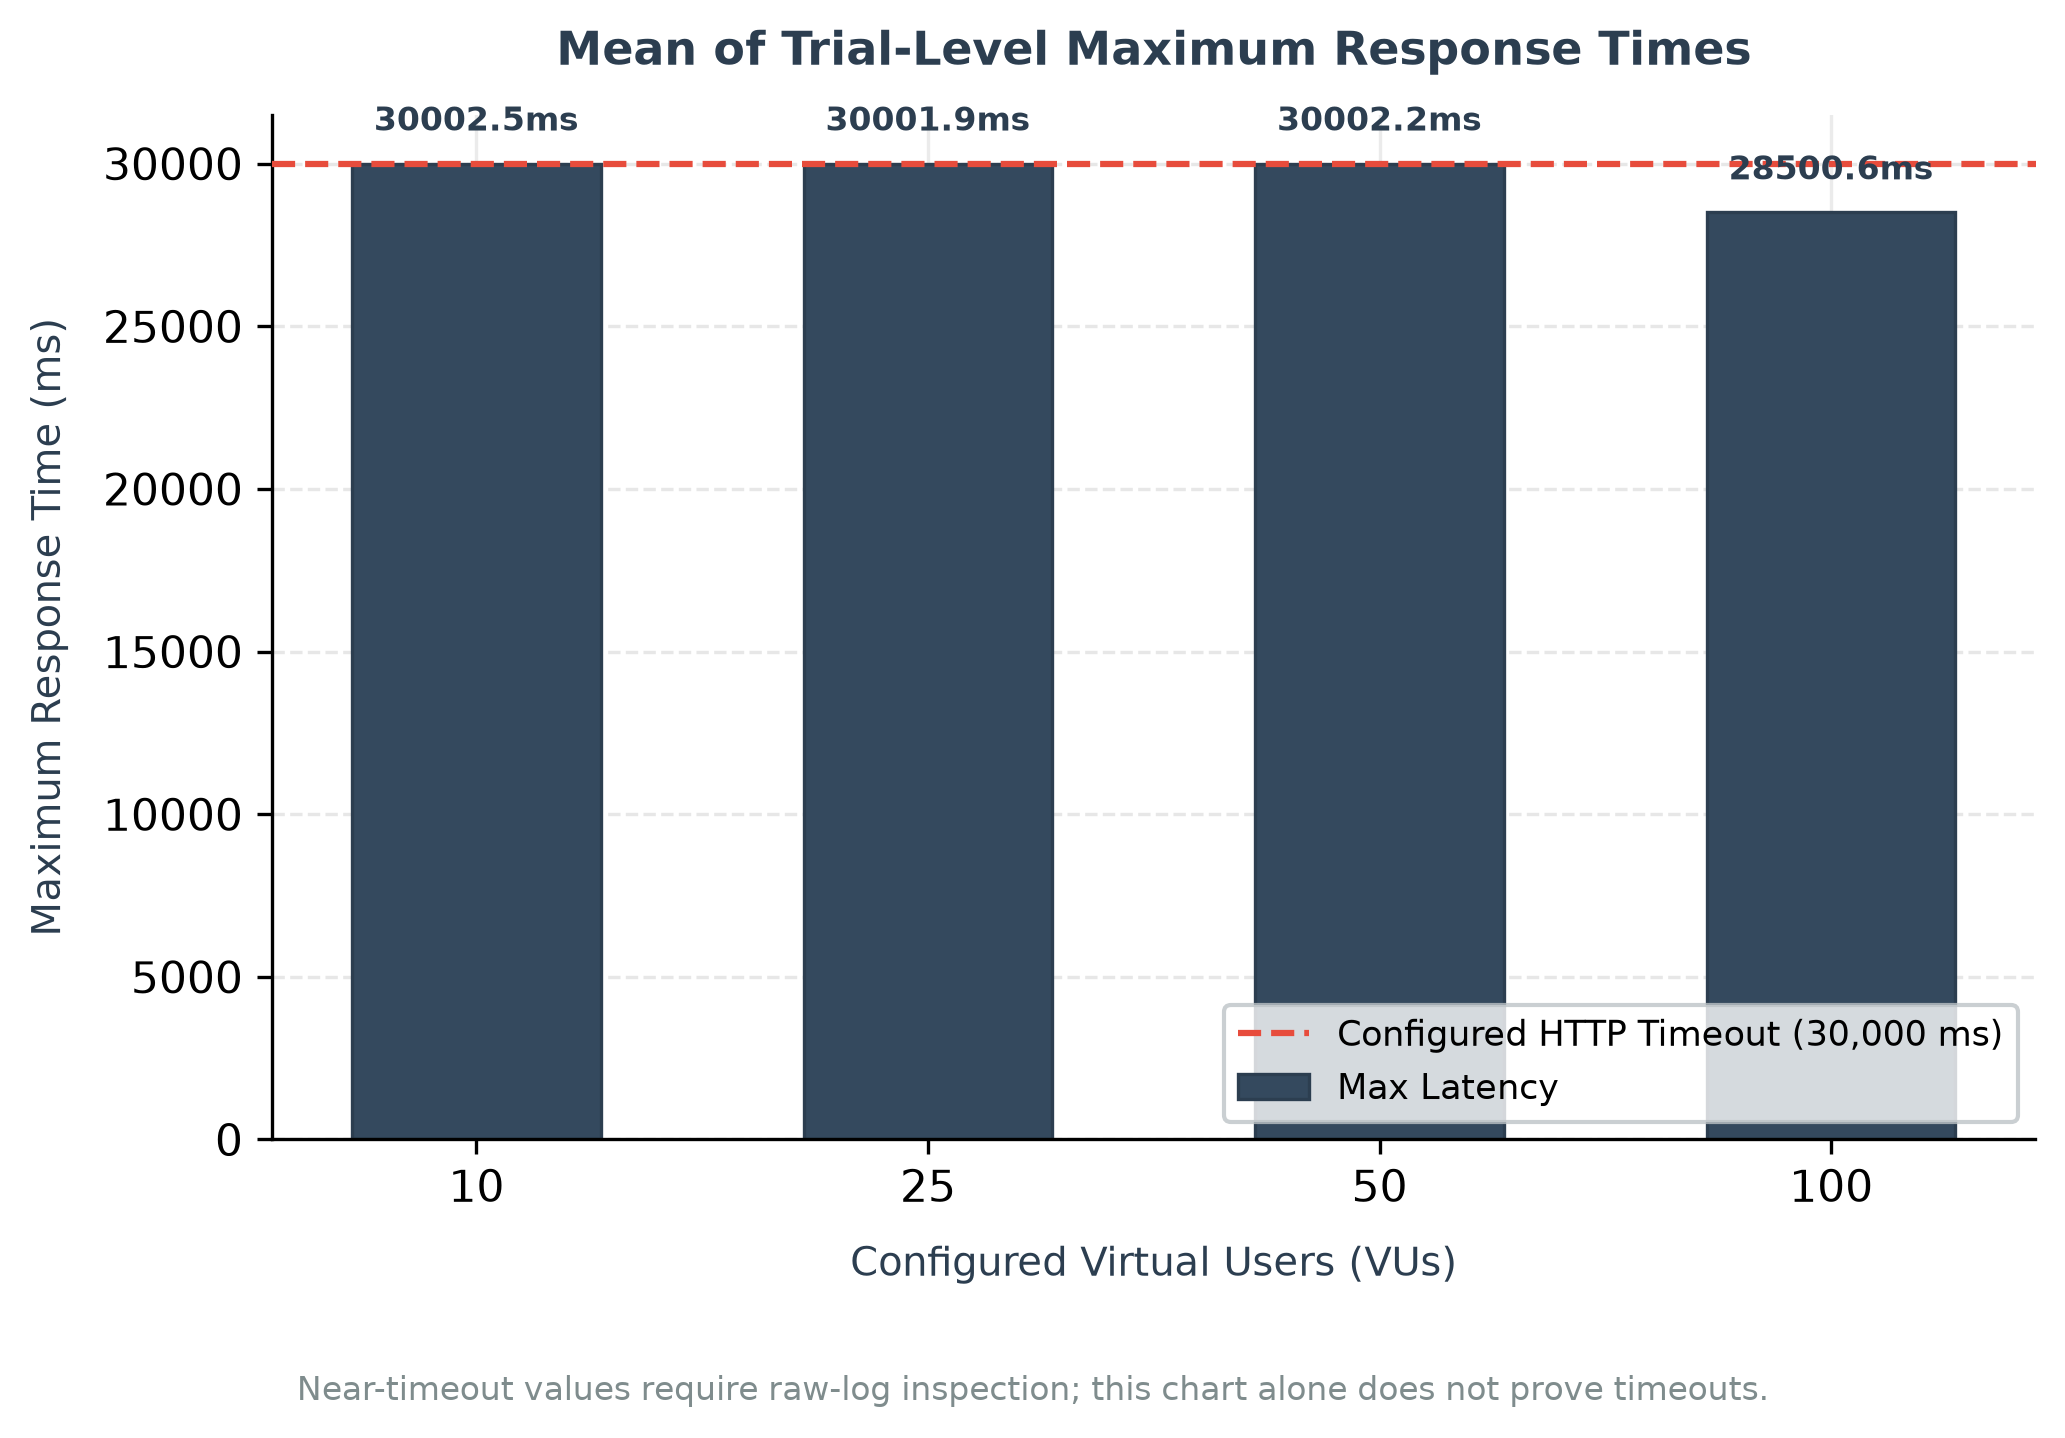

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

x_labels = summary["VUs"].astype(str)
y = summary["Max_Latency_ms_Mean"]  # Corrected column name

# Plot clean, professional bars
bars = ax.bar(
    x_labels,
    y,
    color="#34495e",
    width=0.55,
    edgecolor="#2c3e50",
    linewidth=0.8,
    zorder=2,
    label="Max Latency"
)

# Configured timeout threshold line
ax.axhline(
    30000,
    linestyle="--",
    color="#e74c3c",
    linewidth=1.5,
    zorder=3,
    label="Configured HTTP Timeout (30,000 ms)",
)

# Add direct value labels on top of each bar for instant readability
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}ms",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),  # 6 points vertical offset
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
        color="#2c3e50",
        fontweight="semibold"
    )

ax.set_title("Mean of Trial-Level Maximum Response Times", fontsize=11, fontweight="bold", pad=12, color="#2c3e50")
ax.set_xlabel("Configured Virtual Users (VUs)", fontsize=9.5, labelpad=8, color="#2c3e50")
ax.set_ylabel("Maximum Response Time (ms)", fontsize=9.5, labelpad=8, color="#2c3e50")

# Modern academic look: Remove top & right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle="--", alpha=0.3, zorder=0, axis="y")
ax.legend(frameon=True, facecolor="white", edgecolor="#bdc3c7", fontsize=8.5, loc="lower right")

fig.text(
    0.5, -0.05,
    "Near-timeout values require raw-log inspection; this chart alone does not prove timeouts.",
    ha="center",
    fontsize=8,
    color="#7f8c8d"
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "Figure_4_6_8_max_latency_timeout.png",
    bbox_inches="tight",
    dpi=300,
)
plt.show()
plt.close(fig)

### Export the tables used in Chapter IV

In [22]:
table_46_2 = summary[
    [
        "VUs",
        "Avg_Latency_ms_Mean",
        "Avg_Latency_ms_SD",
        "P95_ms_Mean",
        "P95_ms_SD",
        "P99_ms_Mean",
        "P99_ms_SD",
        "Max_Latency_ms_Mean",
    ]
].copy()

table_46_3 = summary[
    [
        "VUs",
        "RPS_Mean",
        "RPS_SD",
        "Workflow_Completed_Mean",
        "Workflow_Duration_Avg_ms_Mean",
        "Workflow_Duration_P95_ms_Mean",
    ]
].copy()

table_46_3["Throughput_per_VU"] = (
    table_46_3["RPS_Mean"] / table_46_3["VUs"]
)

table_46_4 = summary[
    [
        "VUs",
        "HTTP_Failed_Rate_pct_Mean",
        "HTTP_Failed_Rate_pct_SD",
        "Workflow_Success_Rate_pct_Mean",
        "Workflow_Success_Rate_pct_SD",
    ]
].copy()

table_46_5 = summary[
    ["VUs", "RPS_Mean", "Avg_Latency_ms_Mean"]
].copy()

table_46_5["Throughput_Index"] = (
    table_46_5["RPS_Mean"]
    / table_46_5["RPS_Mean"].iloc[0]
    * 100
)

table_46_5["Latency_Index"] = (
    table_46_5["Avg_Latency_ms_Mean"]
    / table_46_5["Avg_Latency_ms_Mean"].iloc[0]
    * 100
)

table_46_2.to_csv(OUTPUT_DIR / "Table_4_6_2_response_time.csv", index=False)
table_46_3.to_csv(OUTPUT_DIR / "Table_4_6_3_throughput.csv", index=False)
table_46_4.to_csv(OUTPUT_DIR / "Table_4_6_4_reliability.csv", index=False)
table_46_5.to_csv(OUTPUT_DIR / "Table_4_6_5_scalability.csv", index=False)

print("Tables and figures saved to:", OUTPUT_DIR.resolve())

Tables and figures saved to: /Users/arnel/CODES/MMDC/CAPSTONE1/testbed-requirement-analysis/analysis_outputs
